# Visión Computacional: Visión Estéreo y Registración de Imágenes

Este notebook acompaña la unidad de **Visión Estereoscópica y Registración de Imágenes**
y cubre tres ejercicios aplicados, cada uno atacando una parte distinta del pipeline visto en clase:

| Ejercicio | Del pipeline visto en clase... | ...a esto |
|---|---|---|
| 1. Disparidad y profundidad | Paso 3 (Correspondencia) + Paso 4 (Triangulación) | Convertir un mapa de disparidad en una medida real de profundidad, y **validarla contra un ground truth** |
| 2. Registración por características | Alternativa a la rectificación estéreo (misma idea de homografía) | Alinear dos fotos de una escena plana tomadas desde ángulos distintos |
| 3. Registración multimodal (CT/MRI) | Métrica de Información Mutua (mencionada para casos donde SAD/SSD/NCC fallan) | Alinear un CT y una MRI del mismo paciente |

Cada ejercicio tiene: una celda de **descripción**, la **implementación funcionando**, y al final
una lista de **actividades propuestas** para que las resuelvan ustedes.


## Configuración inicial

Instalamos las librerías que no vienen por defecto en Colab. Nota: `pip` puede mostrar una
advertencia sobre una versión de `numpy` incompatible con `stereo-mideval` — es esperable y no
rompe nada porque instalamos esa librería con `--no-deps` (no le dejamos tocar numpy).


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)


OpenCV: 5.0.0


---
## Ejercicio 1 — De la disparidad a la profundidad métrica (con ground truth real)

**Objetivo:** calcular un mapa de disparidad con `cv2.StereoSGBM`, convertirlo a un mapa de
profundidad en metros usando la fórmula $Z = \dfrac{f \cdot B}{d}$, y **validar el resultado**
contra un mapa de disparidad de referencia (ground truth) real — no alcanza con que "se vea bien".

**Dataset:** usamos la escena *Adirondack* del [Middlebury Stereo Dataset 2014](https://vision.middlebury.edu/stereo/data/scenes2014/),
que trae el par estéreo, la calibración (`calib.txt` con foco, baseline y `doffs`) y el mapa de
disparidad de referencia medido con luz estructurada. La descargamos con la librería
[`stereo-mideval`](https://pypi.org/project/stereo-mideval/), que se encarga de bajar el `.zip`
correcto (~72 MB) y parsear todo por nosotros.


In [ ]:
from stereomideval.dataset import Dataset, DatasetType

DATASET_FOLDER = "middlebury_data"
SCENE_NAME = Dataset.Adirondack   # pueden probar otras: Dataset.Motorcycle, Dataset.Piano, etc.

os.makedirs(DATASET_FOLDER, exist_ok=True)
print(f"Descargando la escena '{SCENE_NAME}' (puede tardar uno o dos minutos)...")
Dataset.download_scene_data(SCENE_NAME, DATASET_FOLDER, DatasetType.imperfect)

scene = Dataset.load_scene_data(SCENE_NAME, DATASET_FOLDER, dataset_type=DatasetType.imperfect)
print("Tamaño de las imágenes:", scene.left_image.shape)
print("Rango de disparidad esperado (ndisp):", scene.ndisp)


Descargando la escena 'Adirondack' (puede tardar uno o dos minutos)...
Downloading: 100% [75664727 / 75664727] bytesExtracting zip...
Tamaño de las imágenes: (1984, 2872, 3)
Rango de disparidad esperado (ndisp): 290.0


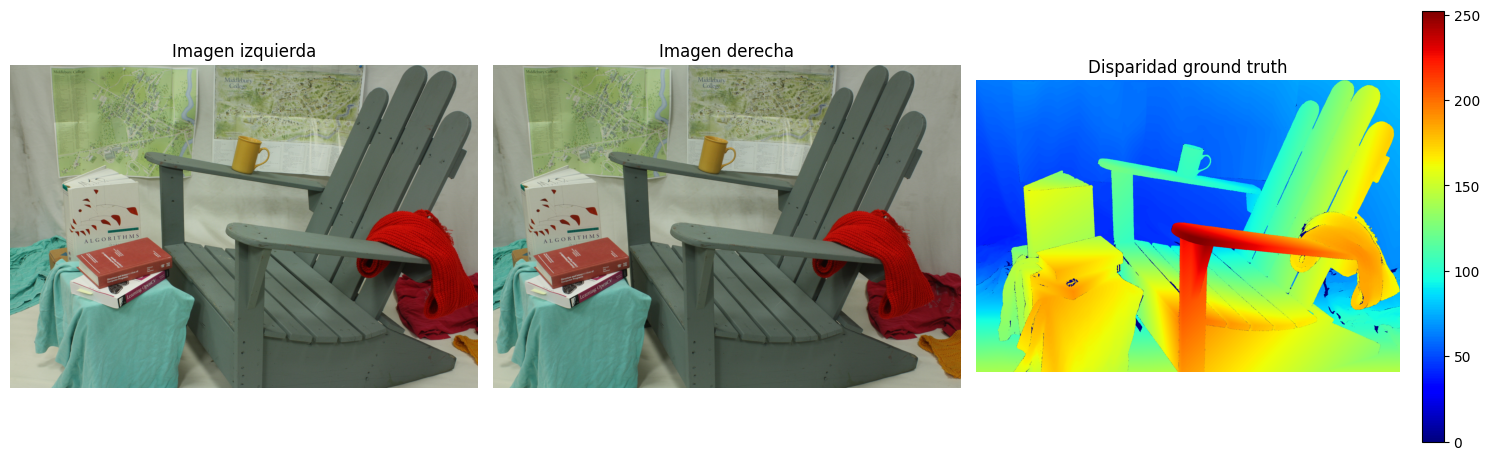

In [ ]:
# Visualizamos el par estéreo y el mapa de disparidad de referencia (ground truth)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(scene.left_image, cv2.COLOR_BGR2RGB)); axes[0].set_title("Imagen izquierda"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(scene.right_image, cv2.COLOR_BGR2RGB)); axes[1].set_title("Imagen derecha"); axes[1].axis("off")
gt_vis = np.where(np.isfinite(scene.disp_image), scene.disp_image, 0)
im = axes[2].imshow(gt_vis, cmap="jet"); axes[2].set_title("Disparidad ground truth"); axes[2].axis("off")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()


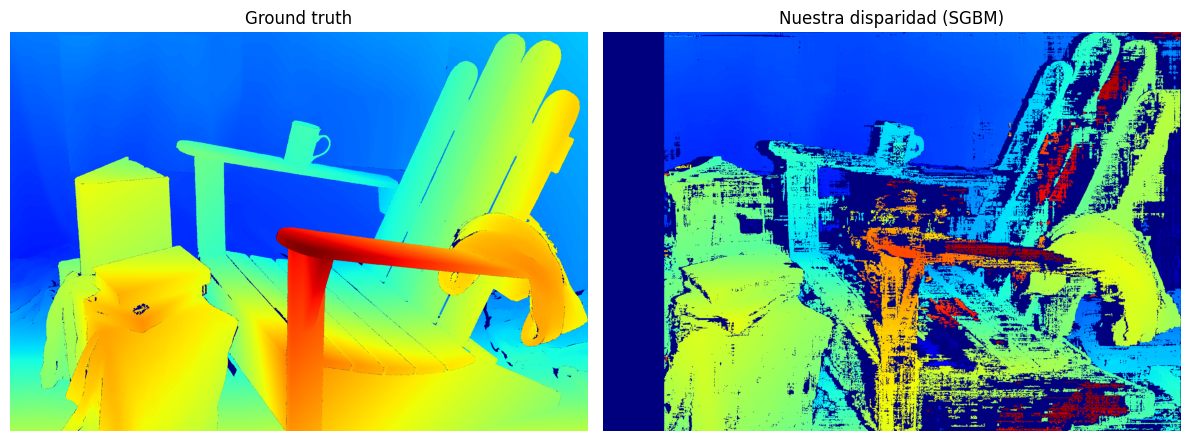

In [ ]:
def calcular_disparidad(imgL_bgr, imgR_bgr, num_disparities=192, block_size=5):
    '''Calcula el mapa de disparidad con StereoSGBM. num_disparities debe ser múltiplo de 16.'''
    grayL = cv2.cvtColor(imgL_bgr, cv2.COLOR_BGR2GRAY)
    grayR = cv2.cvtColor(imgR_bgr, cv2.COLOR_BGR2GRAY)

    stereo = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8 * 3 * block_size ** 2,
        P2=32 * 3 * block_size ** 2,
        disp12MaxDiff=1,
        uniquenessRatio=10,
        speckleWindowSize=100,
        speckleRange=32,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
    )
    disp = stereo.compute(grayL, grayR).astype(np.float32) / 16.0
    return disp

# numDisparities tiene que ser múltiplo de 16 y cubrir el rango que indica el dataset (ndisp)
num_disp = int(np.ceil(scene.ndisp / 16)) * 16
mi_disparidad = calcular_disparidad(scene.left_image, scene.right_image, num_disparities=num_disp, block_size=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(gt_vis, cmap="jet"); axes[0].set_title("Ground truth"); axes[0].axis("off")
axes[1].imshow(np.clip(mi_disparidad, 0, None), cmap="jet"); axes[1].set_title("Nuestra disparidad (SGBM)"); axes[1].axis("off")
plt.tight_layout(); plt.show()


In [ ]:
from stereomideval.eval import Metric

# Enmascaramos los píxeles sin disparidad válida en el ground truth (oclusiones -> inf en el pfm)
valid_mask = np.isfinite(scene.disp_image)
gt_eval = np.where(valid_mask, scene.disp_image, 0).astype(np.float32)
mi_eval = np.where(valid_mask, mi_disparidad, 0).astype(np.float32)

rmse = Metric.calc_rmse(gt_eval, mi_eval)
bad2 = Metric.calc_bad_pix_error(gt_eval, mi_eval, threshold=2.0)

print(f"RMSE (en píxeles de disparidad): {rmse:.2f}")
print(f"Porcentaje de píxeles 'malos' (error > 2 px): {bad2:.1f}%")


RMSE (en píxeles de disparidad): 76.18
Porcentaje de píxeles 'malos' (error > 2 px): 50.2%


Foco: 4152.1 px | Baseline: 176.0 mm | doffs: 213.08
Error medio de profundidad: 6.9 cm
Error mediano de profundidad: 0.4 cm


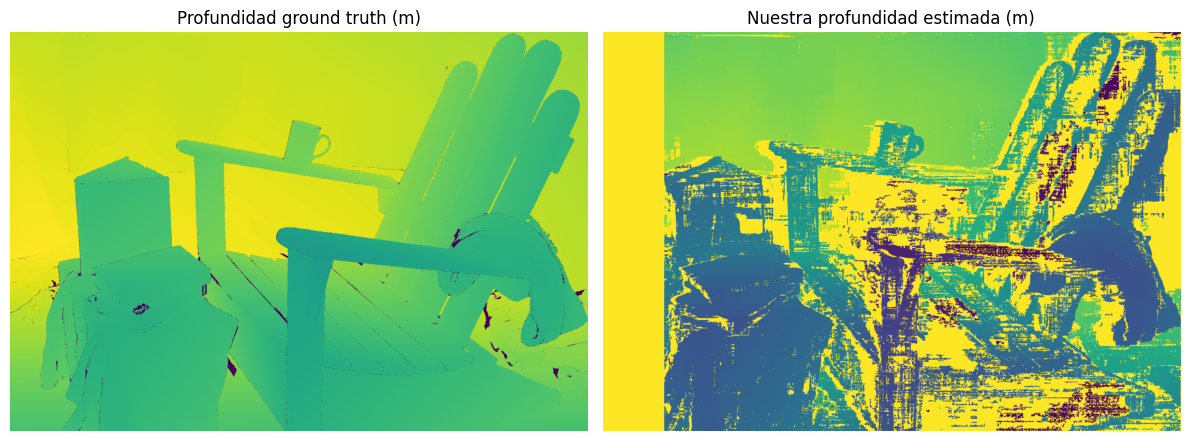

In [ ]:
# Paso de disparidad a profundidad real (metros), usando la calibración de la propia escena
calib_path = os.path.join(DATASET_FOLDER, SCENE_NAME + Dataset.get_perfect_suffix(DatasetType.imperfect), "calib.txt")
cal = Dataset.load_cal(calib_path)
print(f"Foco: {cal.focal_length:.1f} px | Baseline: {cal.baseline:.1f} mm | doffs: {cal.doffs:.2f}")

profundidad_mia = Dataset.disp_to_depth(mi_disparidad, cal.focal_length, cal.doffs, cal.baseline)
profundidad_gt = scene.depth_image  # ya viene calculada a partir del ground truth

# Comparamos el error de profundidad SOLO donde ambas disparidades son válidas y razonables
mask_comparacion = valid_mask & (mi_disparidad > 0) & (profundidad_gt < 5.0)
error_abs_m = np.abs(profundidad_mia - profundidad_gt)[mask_comparacion]

print(f"Error medio de profundidad: {error_abs_m.mean()*100:.1f} cm")
print(f"Error mediano de profundidad: {np.median(error_abs_m)*100:.1f} cm")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(np.clip(profundidad_gt, 0, 3), cmap="viridis"); axes[0].set_title("Profundidad ground truth (m)"); axes[0].axis("off")
axes[1].imshow(np.clip(profundidad_mia, 0, 3), cmap="viridis"); axes[1].set_title("Nuestra profundidad estimada (m)"); axes[1].axis("off")
plt.tight_layout(); plt.show()


### Actividades propuestas — Ejercicio 1

1. **Tuneo de parámetros:** varíen `block_size` (3, 7, 11, 15) y `num_disparities`, y registren cómo cambian el RMSE y el % de píxeles malos. ¿Hay un trade-off entre densidad del mapa y precisión?
2. **BM vs SGBM:** repitan el cálculo con `cv2.StereoBM_create()` en vez de `StereoSGBM_create()` y comparen tiempo de cómputo (usen `%timeit`) contra la calidad (RMSE).
3. **Otra escena:** cambien `SCENE_NAME` por `Dataset.Motorcycle` o `Dataset.Piano` y repitan el análisis. ¿El mismo set de parámetros funciona igual de bien?
4. **Zonas de error:** grafiquen un mapa de error (`|mi_disparidad - ground_truth|`) y describan en qué tipo de regiones de la imagen se concentran los errores más grandes (bordes, zonas sin textura, oclusiones).
5. **(Opcional) Nube de puntos 3D:** usen `cv2.reprojectImageTo3D()` con una matriz Q armada a partir de `cal.focal_length`, `cal.baseline` y `cal.doffs`, y visualicen la nube de puntos con `matplotlib` (scatter 3D) o `open3d`.


### Reflexión y Análisis

1. **Trade-off entre precisión y densidad en la disparidad**:

  >*Situación / Pregunta:* Al modificar el tamaño de ventana (blockSize de 3 a 15) o los parámetros del algoritmo cv2.StereoSGBM_create,
  >* ¿cómo impacta esta variación en las métricas cuantitativas del error cuadrático medio (RMSE) y en el porcentaje de píxeles "malos" (bad-2, píxeles con error superior a 2 px)?
  >* Reflexionen sobre el compromiso (trade-off) entre obtener un mapa de disparidad continuo y denso frente a la pérdida de precisión en las fronteras y bordes de los objetos.

2. **Distribución espacial del error y física de la escena**:

> *Situación / Pregunta:* Al calcular la profundidad en metros mediante la fórmula $Z = \frac{f \cdot B}{d}$ y compararla contra el ground truth,
>   *   ¿en qué regiones específicas de la imagen (como bordes prominentes, zonas homogéneas sin textura u oclusiones) se concentran los mayores errores absolutos?
>   * ¿De qué manera influyen la distancia focal ($f$), la distancia entre cámaras o baseline ($B$) y el desfasaje (doffs) en la incertidumbre de la profundidad a medida que las superficies se alejan?

3. **Eficiencia computacional vs. calidad de reconstrucción** (StereoBM vs. StereoSGBM):

> *Situación / Pregunta*: Si sustituyen el algoritmo de correspondencia semi-global StereoSGBM por el bloque estándar StereoBM,
> * ¿cuál es el impacto en la calidad de la disparidad obtenida y en el tiempo de ejecución en CPU?
> * ¿En qué escenarios prácticos de robótica o visión en tiempo real se justificaría asumir ese deterioro en el RMSE a cambio de menor latencia?

---
## Ejercicio 2 — Registración de imágenes con características (SIFT + Homografía + RANSAC)

**Objetivo:** alinear dos fotos de una **misma escena plana** tomadas desde ángulos distintos,
usando el mismo tipo de homografía que vimos en la rectificación estéreo, pero calculada a partir
de puntos característicos en vez de la geometría de las cámaras.

**Dataset:** usamos el par `graf1.png` / `graf3.png` de los ejemplos oficiales de OpenCV — dos
fotos de una pared con grafitis tomadas desde puntos de vista muy distintos, el par clásico para
probar matching de features. Más abajo pueden reemplazarlas por sus propias fotos.


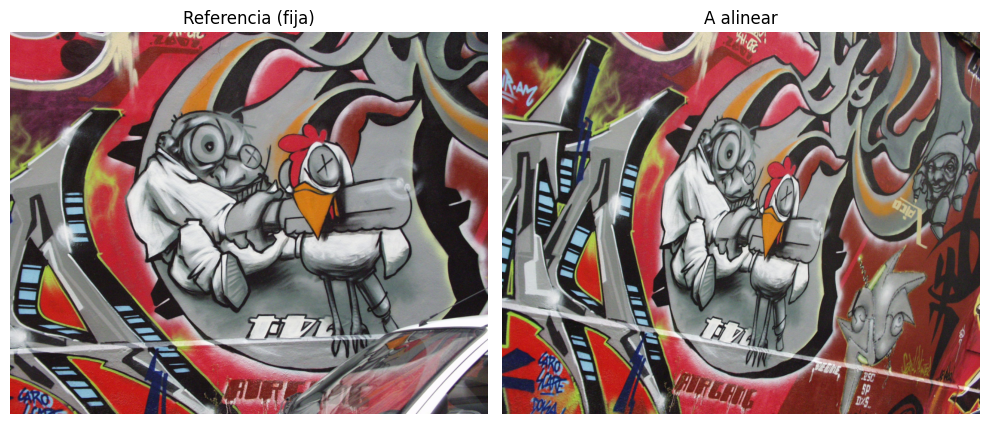

In [ ]:
import urllib.request

def descargar_si_no_existe(nombre, url):
    if not os.path.exists(nombre):
        urllib.request.urlretrieve(url, nombre)
    return nombre

base_url = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
img_referencia_path = descargar_si_no_existe("graf1.png", base_url + "graf1.png")
img_mover_path = descargar_si_no_existe("graf3.png", base_url + "graf3.png")

img_referencia = cv2.imread(img_referencia_path)   # imagen fija (a la que alineamos)
img_mover = cv2.imread(img_mover_path)              # imagen que vamos a alinear

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(img_referencia, cv2.COLOR_BGR2RGB)); axes[0].set_title("Referencia (fija)"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(img_mover, cv2.COLOR_BGR2RGB)); axes[1].set_title("A alinear"); axes[1].axis("off")
plt.tight_layout(); plt.show()


In [ ]:
# Si quieren usar sus propias fotos en vez del par de ejemplo, descomenten esto en Colab:
# from google.colab import files
# subida = files.upload()   # subir 2 archivos: la referencia primero, la que se mueve segundo
# nombres = list(subida.keys())
# img_referencia = cv2.imread(nombres[0])
# img_mover = cv2.imread(nombres[1])


Keypoints -> referencia: 2674 | a alinear: 3506
Matches tras el ratio test: 518 / 3506


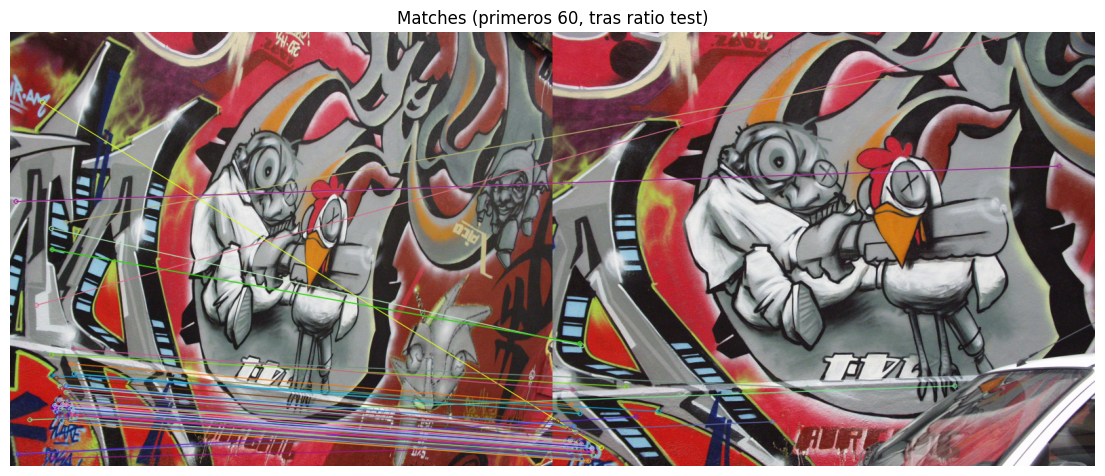

In [ ]:
gray_ref = cv2.cvtColor(img_referencia, cv2.COLOR_BGR2GRAY)
gray_mov = cv2.cvtColor(img_mover, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
kp_ref, des_ref = sift.detectAndCompute(gray_ref, None)
kp_mov, des_mov = sift.detectAndCompute(gray_mov, None)
print(f"Keypoints -> referencia: {len(kp_ref)} | a alinear: {len(kp_mov)}")

bf = cv2.BFMatcher()
matches_knn = bf.knnMatch(des_mov, des_ref, k=2)

# Ratio test de Lowe: nos quedamos solo con matches inequívocos
buenos_matches = [m for m, n in matches_knn if m.distance < 0.75 * n.distance]
print(f"Matches tras el ratio test: {len(buenos_matches)} / {len(matches_knn)}")

img_matches = cv2.drawMatches(img_mover, kp_mov, img_referencia, kp_ref, buenos_matches[:60], None,
                               flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(14, 6))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Matches (primeros 60, tras ratio test)"); plt.show()


In [ ]:
pts_mover = np.float32([kp_mov[m.queryIdx].pt for m in buenos_matches]).reshape(-1, 1, 2)
pts_ref = np.float32([kp_ref[m.trainIdx].pt for m in buenos_matches]).reshape(-1, 1, 2)

H, mask_inliers = cv2.findHomography(pts_mover, pts_ref, cv2.RANSAC, ransacReprojThreshold=5.0)
n_inliers = int(mask_inliers.sum())
print(f"Homografía estimada con RANSAC. Inliers: {n_inliers} / {len(buenos_matches)} ({100*n_inliers/len(buenos_matches):.1f}%)")
print(H)


Homografía estimada con RANSAC. Inliers: 336 / 518 (64.9%)
[[ 1.16019336e+00  3.37872373e-01 -2.35603146e+02]
 [-4.13112514e-01  7.84862696e-01  1.53454725e+02]
 [-4.07930173e-04 -1.03449607e-04  1.00000000e+00]]


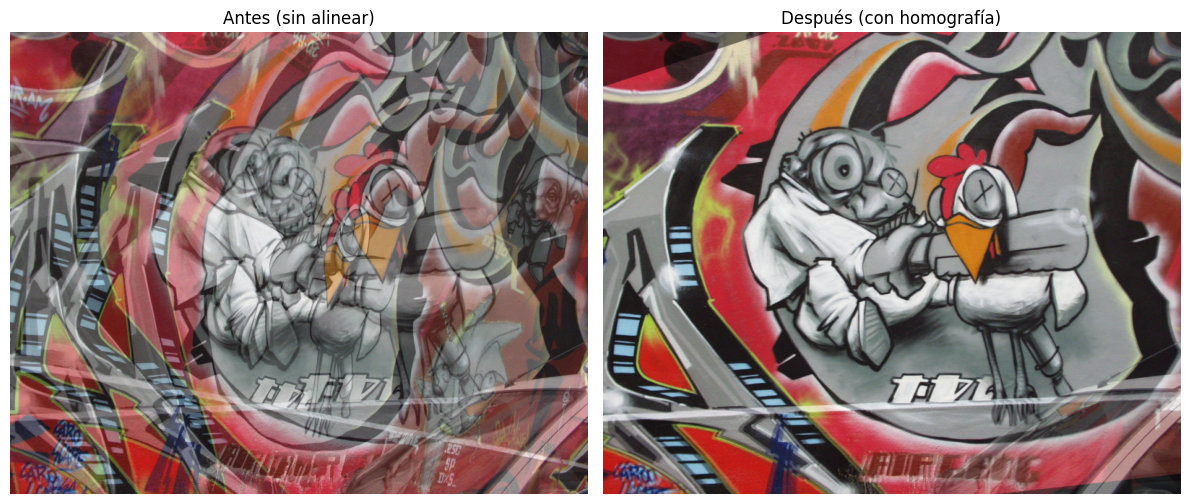

In [ ]:
alto, ancho = img_referencia.shape[:2]
img_alineada = cv2.warpPerspective(img_mover, H, (ancho, alto))

# Comparación antes/después con un blend simple (50/50)
antes = cv2.addWeighted(img_referencia, 0.5, cv2.resize(img_mover, (ancho, alto)), 0.5, 0)
despues = cv2.addWeighted(img_referencia, 0.5, img_alineada, 0.5, 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(antes, cv2.COLOR_BGR2RGB)); axes[0].set_title("Antes (sin alinear)"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(despues, cv2.COLOR_BGR2RGB)); axes[1].set_title("Después (con homografía)"); axes[1].axis("off")
plt.tight_layout(); plt.show()


### Actividades propuestas — Ejercicio 2

1. **SIFT vs ORB:** repitan todo el pipeline con `cv2.ORB_create()` en vez de `cv2.SIFT_create()` (van a necesitar `cv2.NORM_HAMMING` en el matcher). Comparen cantidad de keypoints, cantidad de inliers, y tiempo de ejecución.
2. **Efecto del ratio test:** prueben distintos umbrales (0.6, 0.75, 0.9) en el ratio test de Lowe y observen cómo cambia la cantidad de matches buenos y la calidad final de la homografía.
3. **Sus propias fotos:** saquen dos fotos de una superficie plana (un cuadro, una hoja, una pared) desde ángulos distintos y repitan el ejercicio con la celda de `files.upload()`.
4. **Cuantificar el error de alineación:** elijan 4-5 puntos que puedan identificar a simple vista en ambas imágenes, aplíquenles la homografía manualmente (`cv2.perspectiveTransform`) y midan la distancia en píxeles contra su posición real en la imagen de referencia.
5. **(Opcional) Panorama:** si las imágenes solo se solapan parcialmente (a diferencia de graf1/graf3, que es la misma vista completa), extiendan el canvas de salida y hagan un blend en la zona de solape para armar un mosaico.


### Reflexión y Análisis

1. **Rigurosidad del Ratio Test de Lowe**:
> *Situación / Pregunta*: Al evaluar la unicidad de las correspondencias mediante el criterio $d_1 / d_2 < t$,
> * ¿qué ocurre con la cantidad de coincidencias aceptadas y con la calidad de la homografía resultante cuando el umbral $t$ varía entre valores restrictivos ($0.6$) y permisivos ($0.9$)?
> * Expliquen por qué una baja distancia euclídea individual no garantiza que una correspondencia sea geométricamente correcta.

2. **Robustez a cambios severos de perspectiva (SIFT vs. ORB)**:
> *Situación / Pregunta*: Al comparar el descriptor escalar denso SIFT frente al descriptor binario ORB (evaluado con la distancia de Hamming),
> * ¿cómo responde cada detector ante variaciones extremas de ángulo de visión en planos (como el par de imágenes graf1 y graf3)?
> * Analicen la relación entre la velocidad de cálculo y el porcentaje final de correspondencias válidas (inliers) identificadas por RANSAC.

3. **Sensibilidad de RANSAC al umbral de reproyección**:
> *Situación / Pregunta*: En la estimación de la matriz de homografía $H$ de $3 \times 3$ mediante cv2.findHomography,
> * ¿qué significado geométrico posee el umbral de reproyección (ransacReprojThreshold)?
> * Si este parámetro se fija en un valor extremadamente estricto, ¿cómo afecta la capacidad del modelo para alinear correctamente la imagen mediante cv2.warpPerspective?


---
## Ejercicio 3 — Registración multimodal: CT ↔ MRI con Información Mutua

**Objetivo:** alinear un CT y una resonancia (MRI-T1) **del mismo paciente**. Como vimos en la
teoría, entre modalidades distintas SAD/SSD/NCC no sirven porque la intensidad no se relaciona
linealmente entre ambas (un hueso es brillante en CT y oscuro en MRI). Por eso usamos
**Información Mutua** como métrica de similitud, con [SimpleITK](https://simpleitk.org/).

**Dataset:** `training_001_ct.mha` y `training_001_mr_T1.mha`, el par CT/MRI de cabeza que usa el
propio [tutorial oficial de registración de SimpleITK](https://github.com/InsightSoftwareConsortium/SimpleITK-Notebooks).
Se descarga solo, sin necesidad de crear cuenta en ningún lado.


In [ ]:
!git clone --depth 1 -q https://github.com/InsightSoftwareConsortium/SimpleITK-Notebooks.git

import sys
sys.path.append("SimpleITK-Notebooks/Utilities")
from downloaddata import fetch_data

ct_path = fetch_data("training_001_ct.mha")
mr_path = fetch_data("training_001_mr_T1.mha")
print("CT:", ct_path)
print("MR:", mr_path)


Fetching training_001_ct.mha
Downloaded 15204697 of 15204697 bytes (100.00%)
Fetching training_001_mr_T1.mha
Downloaded 3408209 of 3408209 bytes (100.00%)
CT: /content/SimpleITK-Notebooks/Data/training_001_ct.mha
MR: /content/SimpleITK-Notebooks/Data/training_001_mr_T1.mha


In [ ]:
import SimpleITK as sitk

fixed_image = sitk.ReadImage(ct_path, sitk.sitkFloat32)   # CT: referencia fija
moving_image = sitk.ReadImage(mr_path, sitk.sitkFloat32)  # MRI: la que vamos a alinear

print("Tamaño CT:", fixed_image.GetSize(), "| espaciado:", fixed_image.GetSpacing())
print("Tamaño MRI:", moving_image.GetSize(), "| espaciado:", moving_image.GetSpacing())


Tamaño CT: (512, 512, 29) | espaciado: (0.653595, 0.653595, 4.0)
Tamaño MRI: (256, 256, 26) | espaciado: (1.25, 1.25, 4.0)


El **espaciado** de una imagen 3D (como CT o MRI) se refiere a las dimensiones físicas de cada vóxel (el equivalente 3D de un píxel). Por ejemplo, un espaciado de `(0.65, 0.65, 4.0)` significa que cada vóxel mide 0.65 mm en las direcciones X e Y, y 4.0 mm en la dirección Z (profundidad). Es crucial para la registración, ya que permite que las imágenes de diferentes resoluciones se alineen correctamente en un espacio físico real, no solo en píxeles.

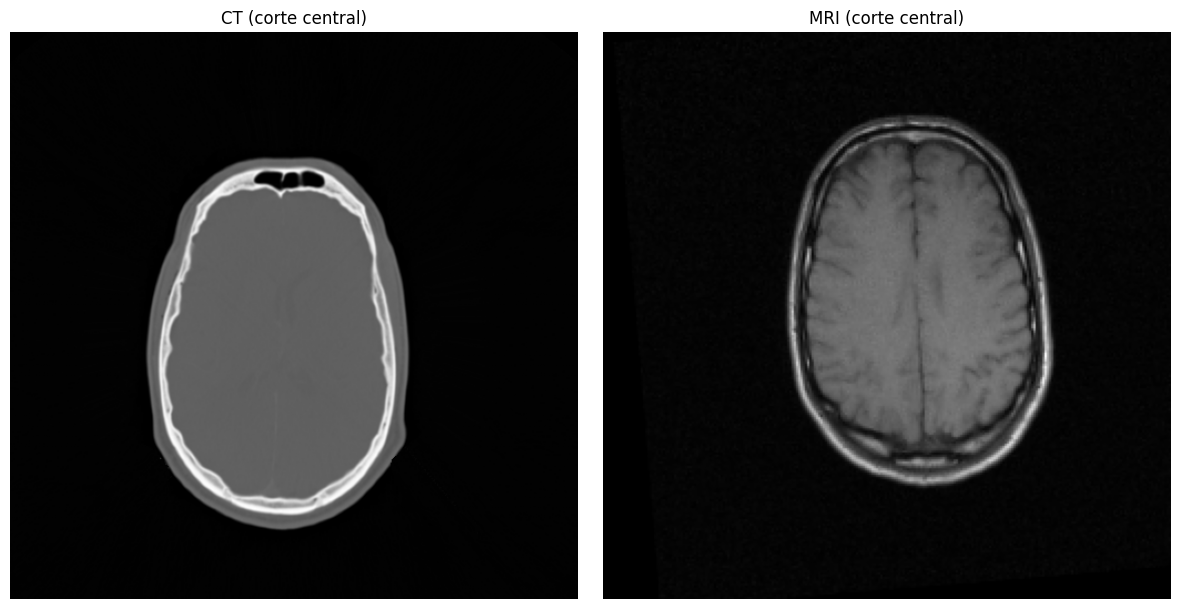

In [ ]:
def slice_central(img_sitk):
    arr = sitk.GetArrayFromImage(img_sitk)   # (z, y, x)
    return arr[arr.shape[0] // 2]

def normalizar_uint8(slice2d):
    return cv2.normalize(slice2d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

slice_ct = normalizar_uint8(slice_central(fixed_image))
slice_mr = normalizar_uint8(slice_central(moving_image))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(slice_ct, cmap="gray"); axes[0].set_title("CT (corte central)"); axes[0].axis("off")
axes[1].imshow(slice_mr, cmap="gray"); axes[1].set_title("MRI (corte central)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

El **checkerboard** es una técnica de visualización que sirve para evaluar visualmente el alineamiento de dos imágenes. Al alternar bloques de la imagen CT y la MRI, se hace muy evidente cualquier desalineación, ya que las estructuras anatómicas no se corresponden en los límites de los bloques. Es una forma rápida e intuitiva de ver si la registración ha sido exitosa.

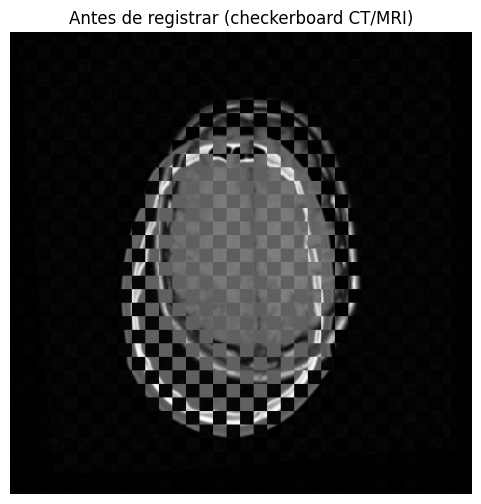

In [ ]:
def slice_central(img_sitk):
    arr = sitk.GetArrayFromImage(img_sitk)   # (z, y, x)
    return arr[arr.shape[0] // 2]

def checkerboard(img_a, img_b, tam_bloque=15):
    '''Arma un checkerboard 2D alternando bloques de dos imágenes ya normalizadas 0-255.'''
    h, w = img_a.shape
    tablero = np.zeros((h, w), dtype=np.uint8)
    for i in range(0, h, tam_bloque):
        for j in range(0, w, tam_bloque):
            bloque = img_a if ((i // tam_bloque) + (j // tam_bloque)) % 2 == 0 else img_b
            tablero[i:i+tam_bloque, j:j+tam_bloque] = bloque[i:i+tam_bloque, j:j+tam_bloque]
    return tablero

def normalizar_uint8(slice2d):
    return cv2.normalize(slice2d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Antes de registrar: remuestreamos la MRI sobre la grilla del CT sin ninguna transformación
# (identidad), solo para poder comparar en el mismo espacio de píxeles.
moving_resampled_antes = sitk.Resample(moving_image, fixed_image, sitk.Transform(),
                                        sitk.sitkLinear, 0.0, moving_image.GetPixelID())

slice_ct = normalizar_uint8(slice_central(fixed_image))
slice_mr_antes = normalizar_uint8(slice_central(moving_resampled_antes))
tablero_antes = checkerboard(slice_ct, slice_mr_antes)

plt.figure(figsize=(6, 6))
plt.imshow(tablero_antes, cmap="gray"); plt.title("Antes de registrar (checkerboard CT/MRI)"); plt.axis("off")
plt.show()


In [ ]:
# Transformación inicial: alineamos los centros geométricos de ambos volúmenes
initial_transform = sitk.CenteredTransformInitializer(
    fixed_image, moving_image, sitk.Euler3DTransform(),
    sitk.CenteredTransformInitializerFilter.GEOMETRY
)

registration_method = sitk.ImageRegistrationMethod()

# --- Métrica: Información Mutua (Mattes) -> la que sirve para multimodal ---
registration_method.SetMetricAsMattesMutualInformation(numberOfHistogramBins=50)
registration_method.SetMetricSamplingStrategy(registration_method.RANDOM)
registration_method.SetMetricSamplingPercentage(0.2)
registration_method.SetInterpolator(sitk.sitkLinear)

# --- Optimizador ---
registration_method.SetOptimizerAsGradientDescent(
    learningRate=1.0, numberOfIterations=200,
    convergenceMinimumValue=1e-6, convergenceWindowSize=10
)
registration_method.SetOptimizerScalesFromPhysicalShift()

# --- Estrategia multi-resolución (grueso -> fino), acelera y evita mínimos locales ---
registration_method.SetShrinkFactorsPerLevel(shrinkFactors=[4, 2, 1])
registration_method.SetSmoothingSigmasPerLevel(smoothingSigmas=[2, 1, 0])
registration_method.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

registration_method.SetInitialTransform(initial_transform, inPlace=False)

final_transform = registration_method.Execute(fixed_image, moving_image)

print("Métrica final (Información Mutua, más negativo = mejor alineación):", registration_method.GetMetricValue())
print("Motivo de parada:", registration_method.GetOptimizerStopConditionDescription())


Métrica final (Información Mutua, más negativo = mejor alineación): -0.6161926521330469
Motivo de parada: GradientDescentOptimizerv4Template: Convergence checker passed at iteration 13.


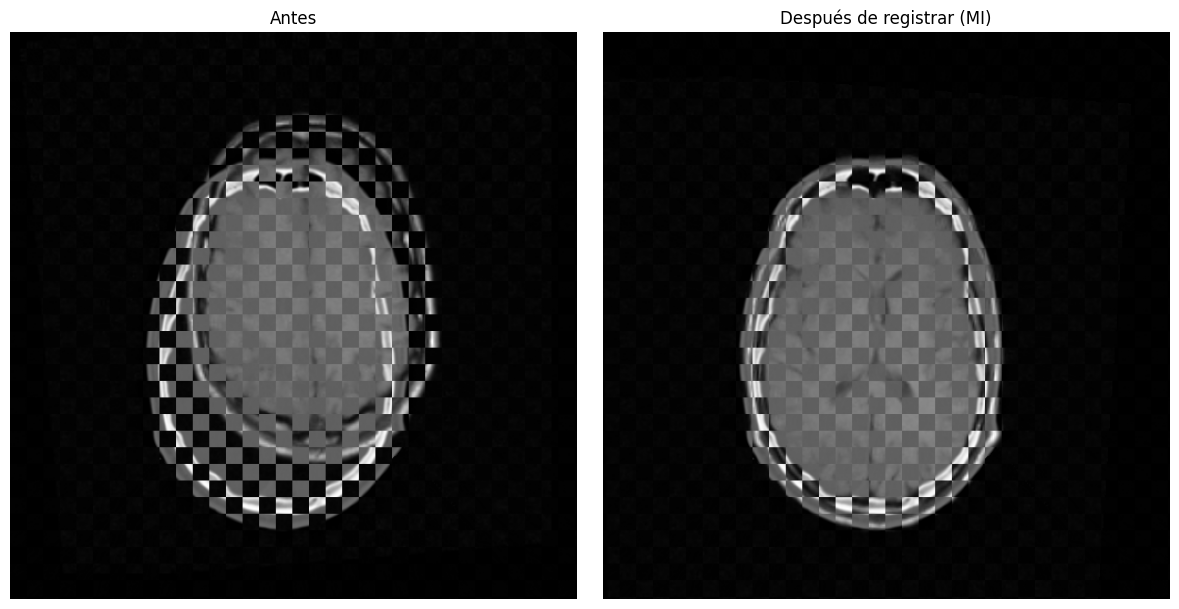

In [ ]:
moving_resampled_despues = sitk.Resample(moving_image, fixed_image, final_transform,
                                          sitk.sitkLinear, 0.0, moving_image.GetPixelID())

slice_mr_despues = normalizar_uint8(slice_central(moving_resampled_despues))
tablero_despues = checkerboard(slice_ct, slice_mr_despues)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(tablero_antes, cmap="gray"); axes[0].set_title("Antes"); axes[0].axis("off")
axes[1].imshow(tablero_despues, cmap="gray"); axes[1].set_title("Después de registrar (MI)"); axes[1].axis("off")
plt.tight_layout(); plt.show()


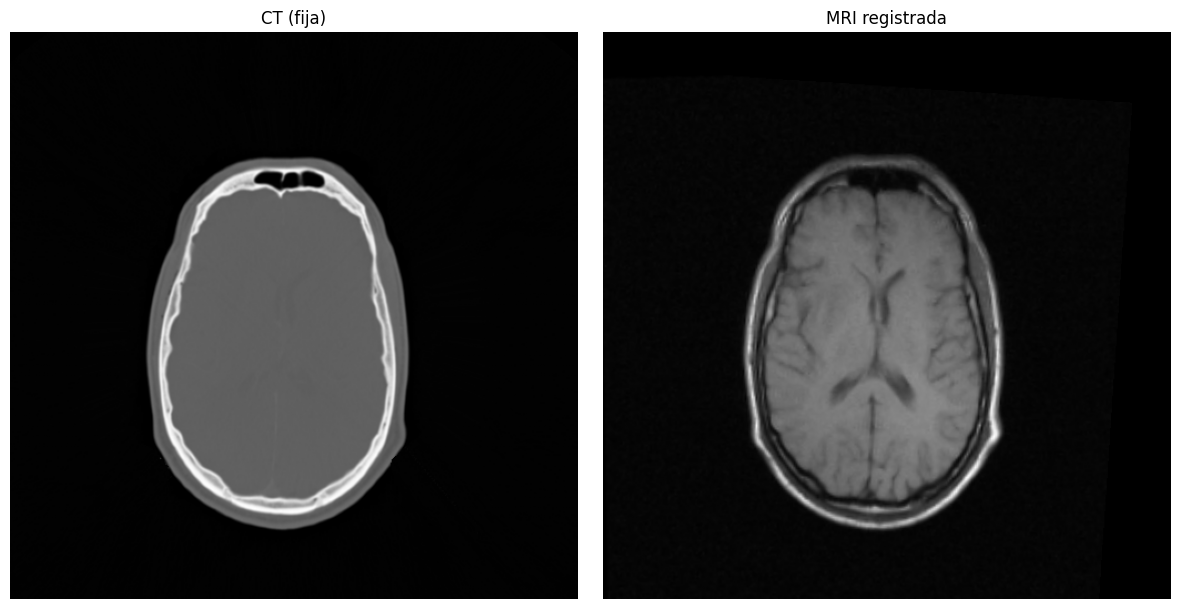

In [ ]:
slice_ct_final = normalizar_uint8(slice_central(fixed_image))
slice_mr_final_registered = normalizar_uint8(slice_central(moving_resampled_despues))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(slice_ct_final, cmap="gray"); axes[0].set_title("CT (fija)"); axes[0].axis("off")
axes[1].imshow(slice_mr_final_registered, cmap="gray"); axes[1].set_title("MRI registrada"); axes[1].axis("off")
plt.tight_layout(); plt.show()

### Actividades propuestas — Ejercicio 3

1. **MI vs correlación:** repitan la registración cambiando `SetMetricAsMattesMutualInformation()` por `SetMetricAsCorrelation()` (o `SetMetricAsMeanSquares()`). Comparen el resultado en el checkerboard — ¿converge igual de bien? Este es el punto clave: mostrar en la práctica por qué la teoría dice que hay que usar MI entre modalidades distintas.
2. **Robustez a la inicialización:** desplacen manualmente el `initial_transform` antes de optimizar (por ejemplo, sumen 20 mm en algún eje con `SetTranslation`) y vean si el optimizador todavía converge o se queda en un mínimo local.
3. **Otro corte:** en vez de mostrar el corte axial central (`arr.shape[0] // 2`), prueben otros índices de corte, o hagan un corte coronal/sagital cambiando qué eje del array indexan.
4. **Cuantificar la mejora:** además de mirar el checkerboard, impriman el valor de la métrica de MI evaluada en la transformación inicial (identidad) vs la final, para tener un número objetivo de cuánto mejoró.
5. **(Opcional) Deformable:** probar un registro no-rígido (`sitk.BSplineTransformInitializer`) después del rígido, y comparar si mejora la alineación en zonas donde el rígido no alcanza (por ejemplo, si hay pequeñas diferencias de forma entre CT y MRI).


### Reflexión y Análisis

1. **Insuficiencia de métricas clásicas (SSD/NCC) en imágenes multimodales**:
> *Situación / Pregunta*: Considerando que el tejido óseo presenta alta intensidad en una tomografía (CT) pero aparece oscuro en una resonancia magnética (MRI-T1),
> * ¿por qué las métricas de suma de diferencias al cuadrado (SSD) o correlación lineal fallan al intentar registrar ambas modalidades?
> * Expliquen por qué la Información Mutua (Mattes) logra guiar la alineación evaluando la entropía y dependencia estadística global entre las imágenes.

2. **Evaluación diagnóstica con Checkerboard y espacio físico**:
> *Situación / Pregunta*: Al analizar la alineación mediante la técnica del tablero de ajedrez alternado (checkerboard) antes y después de la registración,
> * ¿qué discontinuidades en las estructuras anatómicas permiten confirmar visualmente si la transformación rígida (Euler3DTransform) fue correcta?
> * ¿Por qué es crítico considerar el espaciado físico del vóxel (en mm) y no solo la resolución en píxeles al registrar imágenes médicas 3D?

3. **Sensibilidad a la inicialización y estrategia multirresolución**:
> *Situación / Pregunta*: Si se introduce una perturbación o desplazamiento manual severo al transformador inicial (initial_transform) antes de la optimización por descenso de gradiente,
> * ¿el sistema logra converger a la solución correcta o cae en un mínimo local?
> * ¿Qué papel desempeñan las pirámides de multirresolución (shrinkFactors y smoothingSigmas) para expandir la cuenca de atracción del optimizador?